Membuat graph 5 vertex berarah dan tidak berarah, menggunakan network kx

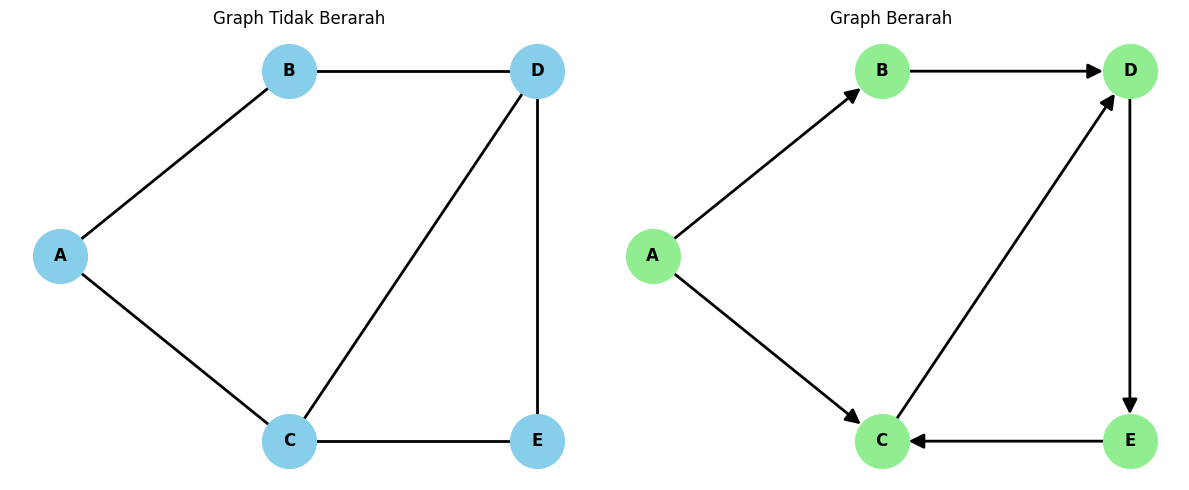

In [ ]:

import networkx as nx
import matplotlib.pyplot as plt

# ==========================
# 1. GRAPH TIDAK BERARAH
# ==========================
G1 = nx.Graph()

G1.add_nodes_from(["A", "B", "C", "D", "E"])

G1.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("C", "E"),
    ("D", "E")
])

# ==========================
# 2. GRAPH BERARAH
# ==========================
G2 = nx.DiGraph()

G2.add_nodes_from(["A", "B", "C", "D", "E"])

G2.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("D", "E"),
    ("E", "C")
])

# Posisi vertex
pos = {
    "A": (0, 1),
    "B": (1.2, 1.7),
    "C": (1.2, 0.3),
    "D": (2.5, 1.7),
    "E": (2.5, 0.3)
}

# Visualisasi
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Graph tidak berarah
nx.draw(
    G1, pos, ax=ax[0],
    with_labels=True,
    node_color="skyblue",
    node_size=1500,
    font_weight="bold",
    width=2
)
ax[0].set_title("Graph Tidak Berarah")

# Graph berarah
nx.draw(
    G2, pos, ax=ax[1],
    with_labels=True,
    node_color="lightgreen",
    node_size=1500,
    font_weight="bold",
    arrows=True,
    arrowsize=22,
    width=2
)
ax[1].set_title("Graph Berarah")

plt.tight_layout()
plt.show()


menghitung degree

In [ ]:
import networkx as nx

# Graph tidak berarah
G1 = nx.Graph()
G1.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("C", "E"),
    ("D", "E")
])

print("DEGREE GRAPH TIDAK BERARAH")
for vertex, degree in G1.degree():
    print(vertex, "=", degree)


# Graph berarah
G2 = nx.DiGraph()
G2.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("D", "E"),
    ("E", "C")
])

print("\nDEGREE GRAPH BERARAH")
for vertex in G2.nodes():
    print(
        vertex,
        "| In-Degree =", G2.in_degree(vertex),
        "| Out-Degree =", G2.out_degree(vertex),
        "| Total Degree =", G2.degree(vertex)
    )

DEGREE GRAPH TIDAK BERARAH
A = 2
B = 2
C = 3
D = 3
E = 2

DEGREE GRAPH BERARAH
A | In-Degree = 0 | Out-Degree = 2 | Total Degree = 2
B | In-Degree = 1 | Out-Degree = 1 | Total Degree = 2
C | In-Degree = 2 | Out-Degree = 1 | Total Degree = 3
D | In-Degree = 2 | Out-Degree = 1 | Total Degree = 3
E | In-Degree = 1 | Out-Degree = 1 | Total Degree = 2


distribusi derajatnya


 Distribusi Degree Undirected Graph
Degree | Frekuensi | Distribusi
2 | 3 | 0.6
3 | 2 | 0.4


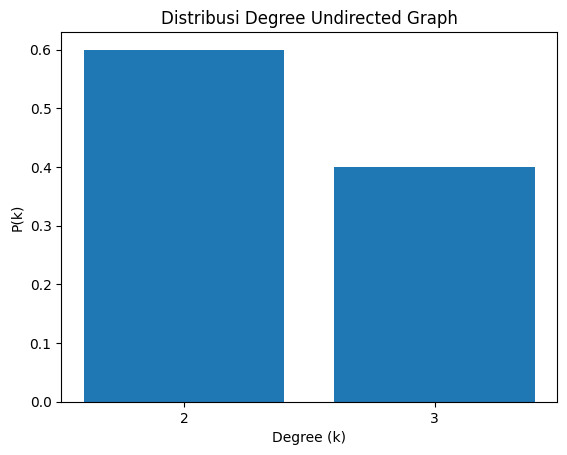


 Distribusi In-Degree Directed Graph
Degree | Frekuensi | Distribusi
0 | 1 | 0.2
1 | 2 | 0.4
2 | 2 | 0.4


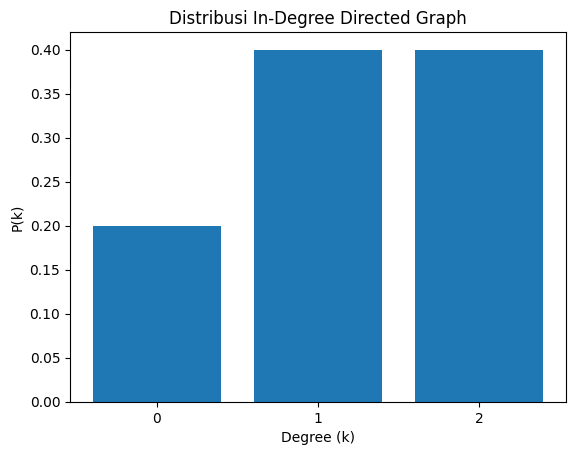


 Distribusi Out-Degree Directed Graph
Degree | Frekuensi | Distribusi
1 | 4 | 0.8
2 | 1 | 0.2


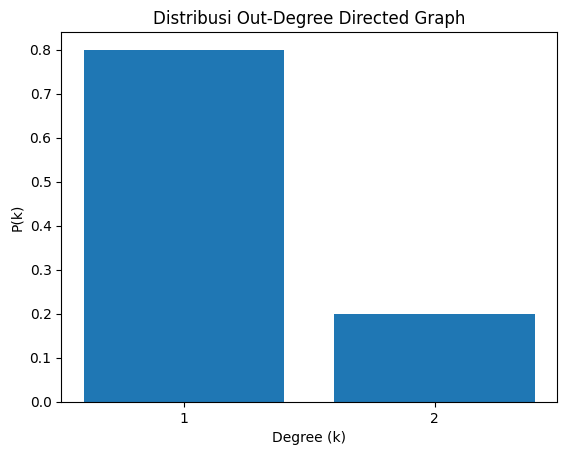


 Distribusi Total Degree Directed Graph
Degree | Frekuensi | Distribusi
2 | 3 | 0.6
3 | 2 | 0.4


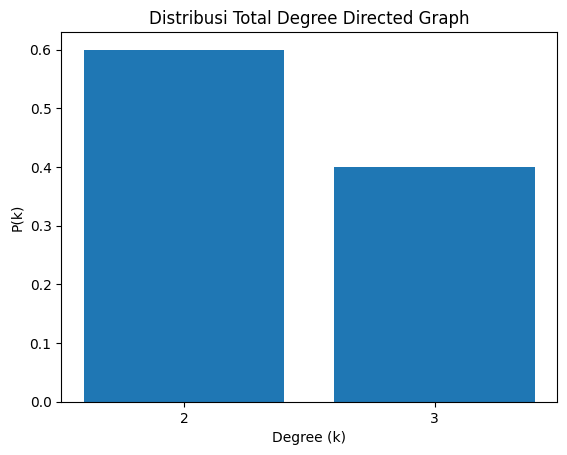

In [ ]:

import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

# Graph tidak berarah
G1 = nx.Graph()
G1.add_edges_from([
    ("A", "B"), ("A", "C"),
    ("B", "D"), ("C", "D"),
    ("C", "E"), ("D", "E")
])

# Graph berarah
G2 = nx.DiGraph()
G2.add_edges_from([
    ("A", "B"), ("A", "C"),
    ("B", "D"), ("C", "D"),
    ("D", "E"), ("E", "C")
])

def distribusi_degree(degree_list, judul):
    frekuensi = Counter(degree_list)
    total = len(degree_list)

    print("\n", judul)
    print("Degree | Frekuensi | Distribusi")

    for k in sorted(frekuensi):
        jumlah = frekuensi[k]
        pk = jumlah / total
        print(k, "|", jumlah, "|", round(pk, 2))

    # Grafik distribusi
    plt.bar(
        frekuensi.keys(),
        [v / total for v in frekuensi.values()]
    )
    plt.xlabel("Degree (k)")
    plt.ylabel("P(k)")
    plt.title(judul)
    plt.xticks(sorted(frekuensi.keys()))
    plt.show()

# Distribusi graph tidak berarah
distribusi_degree(
    [d for v, d in G1.degree()],
    "Distribusi Degree Undirected Graph"
)

# Distribusi In-Degree
distribusi_degree(
    [d for v, d in G2.in_degree()],
    "Distribusi In-Degree Directed Graph"
)

# Distribusi Out-Degree
distribusi_degree(
    [d for v, d in G2.out_degree()],
    "Distribusi Out-Degree Directed Graph"
)

# Distribusi Total Degree
distribusi_degree(
    [d for v, d in G2.degree()],
    "Distribusi Total Degree Directed Graph"
)


Avrage Degree

In [ ]:

import networkx as nx

# Graph tidak berarah
G1 = nx.Graph()
G1.add_edges_from([
    ("A", "B"), ("A", "C"),
    ("B", "D"), ("C", "D"),
    ("C", "E"), ("D", "E")
])

# Graph berarah
G2 = nx.DiGraph()
G2.add_edges_from([
    ("A", "B"), ("A", "C"),
    ("B", "D"), ("C", "D"),
    ("D", "E"), ("E", "C")
])

# Average Degree Undirected
avg_undirected = sum(dict(G1.degree()).values()) / G1.number_of_nodes()

# Average Degree Directed
avg_in = sum(dict(G2.in_degree()).values()) / G2.number_of_nodes()
avg_out = sum(dict(G2.out_degree()).values()) / G2.number_of_nodes()
avg_total = sum(dict(G2.degree()).values()) / G2.number_of_nodes()

print("Average Degree Undirected:", avg_undirected)
print("Average In-Degree:", avg_in)
print("Average Out-Degree:", avg_out)
print("Average Total Degree:", avg_total)


Average Degree Undirected: 2.4
Average In-Degree: 1.2
Average Out-Degree: 1.2
Average Total Degree: 2.4


hitung kepadatan

In [ ]:

import networkx as nx

# Graph tidak berarah
G1 = nx.Graph()
G1.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("C", "E"),
    ("D", "E")
])

# Graph berarah
G2 = nx.DiGraph()
G2.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("D", "E"),
    ("E", "C")
])

# Menghitung density
density_undirected = nx.density(G1)
density_directed = nx.density(G2)

print("Undirected Graph Density:", density_undirected)
print("Directed Graph Density:", density_directed)

print("Undirected Density (%):", density_undirected * 100, "%")
print("Directed Density (%):", density_directed * 100, "%")


Undirected Graph Density: 0.6
Directed Graph Density: 0.3
Undirected Density (%): 60.0 %
Directed Density (%): 30.0 %


matriks agency

In [ ]:

import networkx as nx
import pandas as pd

# Membuat graph tidak berarah
G1 = nx.Graph()

G1.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("C", "E"),
    ("D", "E")
])

# Membuat graph berarah
G2 = nx.DiGraph()

G2.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("D", "E"),
    ("E", "C")
])

# Urutan vertex
nodes = ["A", "B", "C", "D", "E"]

# Matriks adjacency undirected
matrix1 = nx.to_numpy_array(
    G1, nodelist=nodes, dtype=int
)

print("MATRiks ADJACENCY GRAPH TIDAK BERARAH")
print(pd.DataFrame(matrix1, index=nodes, columns=nodes))

# Matriks adjacency directed
matrix2 = nx.to_numpy_array(
    G2, nodelist=nodes, dtype=int
)

print("\nMATRIKS ADJACENCY GRAPH BERARAH")
print(pd.DataFrame(matrix2, index=nodes, columns=nodes))


MATRiks ADJACENCY GRAPH TIDAK BERARAH
   A  B  C  D  E
A  0  1  1  0  0
B  1  0  0  1  0
C  1  0  0  1  1
D  0  1  1  0  1
E  0  0  1  1  0

MATRIKS ADJACENCY GRAPH BERARAH
   A  B  C  D  E
A  0  1  1  0  0
B  0  0  0  1  0
C  0  0  0  1  0
D  0  0  0  0  1
E  0  0  1  0  0


koefisien klasterisasi

UNDIRECTED GRAPH
A = 0
B = 0
C = 0.333
D = 0.333
E = 1.0
Average Clustering: 0.333

DIRECTED GRAPH
A = 0
B = 0
C = 0.167
D = 0.167
E = 0.5
Average Clustering: 0.167


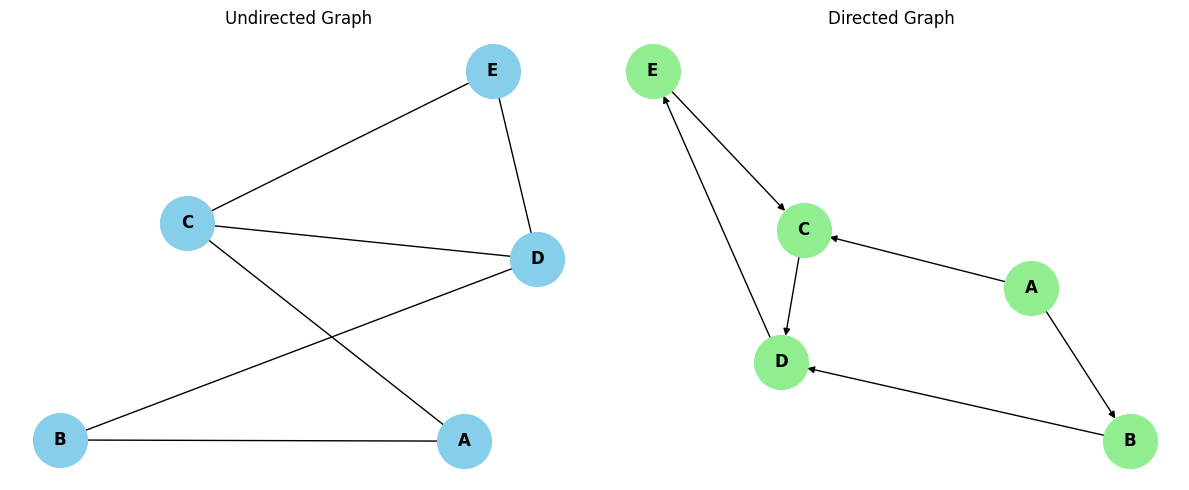

In [ ]:

import networkx as nx
import matplotlib.pyplot as plt

# Graph tidak berarah
G1 = nx.Graph()
G1.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("C", "E"),
    ("D", "E")
])

# Graph berarah
G2 = nx.DiGraph()
G2.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("D", "E"),
    ("E", "C")
])

# Clustering coefficient undirected
print("UNDIRECTED GRAPH")
for v, c in nx.clustering(G1).items():
    print(v, "=", round(c, 3))

avg1 = nx.average_clustering(G1)
print("Average Clustering:", round(avg1, 3))

# Clustering coefficient directed
print("\nDIRECTED GRAPH")
for v, c in nx.clustering(G2).items():
    print(v, "=", round(c, 3))

avg2 = nx.average_clustering(G2)
print("Average Clustering:", round(avg2, 3))

# Visualisasi perbandingan
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

nx.draw(G1, with_labels=True, node_color="skyblue",
        node_size=1500, font_weight="bold", ax=ax[0])
ax[0].set_title("Undirected Graph")

nx.draw(G2, with_labels=True, node_color="lightgreen",
        node_size=1500, font_weight="bold",
        arrows=True, ax=ax[1])
ax[1].set_title("Directed Graph")

plt.tight_layout()
plt.show()


diameter jarak terpendeknya

In [ ]:

import networkx as nx

# Graph tidak berarah
G1 = nx.Graph()
G1.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("C", "E"),
    ("D", "E")
])

# Graph berarah
G2 = nx.DiGraph()
G2.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("D", "E"),
    ("E", "C")
])

# Diameter undirected
print("Diameter Undirected:", nx.diameter(G1))

# Diameter directed
if nx.is_strongly_connected(G2):
    print("Diameter Directed:", nx.diameter(G2))
else:
    print("Directed Graph tidak strongly connected")

    # Menghitung SCC terbesar
    scc = max(
        nx.strongly_connected_components(G2),
        key=len
    )

    subgraph = G2.subgraph(scc).copy()

    print("SCC terbesar:", scc)
    print("Diameter SCC:", nx.diameter(subgraph))


Diameter Undirected: 2
Directed Graph tidak strongly connected
SCC terbesar: {'C', 'D', 'E'}
Diameter SCC: 2
